In [1]:
# Let numpy stay at 2.x - just reinstall tiatoolbox cleanly
!pip install "numpy>=2.0" -q
!pip install tiatoolbox segmentation-models-pytorch openslide-python shapely geojson -q --upgrade

print("Done. Now go to Kernel → Restart Kernel before continuing.")

Done. Now go to Kernel → Restart Kernel before continuing.


In [1]:
import os
import json
import glob
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, random_split
from PIL import Image, ImageDraw
from shapely.geometry import shape, Polygon, MultiPolygon
import openslide
import segmentation_models_pytorch as smp
import geojson
from skimage import measure
import matplotlib.pyplot as plt
import traceback

print("Torch version:", torch.__version__)
print("GPU available:", torch.cuda.is_available())
print("OpenSlide version:", openslide.__version__)

Torch version: 2.12.0
GPU available: False
OpenSlide version: 1.4.3


In [3]:
BASE_DIR = "/Users/seymour/Downloads/Shomaiya/red_nucleus"

SLIDE_DIR   = BASE_DIR
GEOJSON_DIR = BASE_DIR
PATCH_DIR   = os.path.join(BASE_DIR, "Patch")
MODEL_DIR   = os.path.join(BASE_DIR, "Model")
PRED_DIR    = os.path.join(BASE_DIR, "Pred")

TRAINING_SLIDES = [
    "NPB139_LHE_B10",
    "NPB139_LHE_B17",
    "NPBB2_LHE_B21",
    "NPBB3_LHE_B10",
    "NPBB8_LHE_B11",
    "NPBB28_LHE_B10",
    "NPBB29_LHE_B11",
    "NPBB33_LHE_B10_DUPLICATE",
    "NPBB118_LHE_B10",
    "NPBB130_LHE_B10",
    "NPBB229_LHE_B3",
    "NPBB238_LHE_B2",
    "NPBB246_LHE_B2",
    "NPBB280_LHE_B2",
    "NPBB318_LHE_B2",
    "NPBB393_LHE_B2",
    "NPBB409_LHE_B2",
    "NPBB412_LHE_B2",
    "NPBB415_LHE_B2",
]
# Add this to Cell 3
REFERENCE_SLIDE = os.path.join(SLIDE_DIR, "NPBB8_LHE_B11.svs")
# Change to whichever of your 6 SVS slides has the clearest staining
# Lower resolution = smaller image = fewer patches
# Higher level number = lower resolution
# We use level 2 in geojson_to_mask — this controls patch count
RESOLUTION = 1.25
PATCH_SIZE  = 256  # reduced from 512 — gives 4x more patches

for d in [PATCH_DIR, MODEL_DIR, PRED_DIR]:
    os.makedirs(d, exist_ok=True)

# ── Verify files exist ───────────────────────────────────
print("Checking files...\n")

for name in TRAINING_SLIDES:
    slide_path = os.path.join(SLIDE_DIR, name + ".svs")

    # This allows filenames like:
    # NPBB8_LHE_B11_SA_Jan_2026.geojson
    geojson_matches = glob.glob(os.path.join(GEOJSON_DIR, name + "*.geojson"))

    print(name)
    print("  SVS:    ", "OK" if os.path.exists(slide_path) else "MISSING")
    print("  GeoJSON:", "OK" if geojson_matches else "MISSING")

    if geojson_matches:
        print("  using:  ", os.path.basename(geojson_matches[0]))

    print()

print("Folders ready")

print("Folders ready")

Checking files...

NPB139_LHE_B10
  SVS:     OK
  GeoJSON: OK
  using:   NPB139_LHE_B10_RN.geojson

NPB139_LHE_B17
  SVS:     OK
  GeoJSON: OK
  using:   NPB139_LHE_B17_RN.geojson

NPBB2_LHE_B21
  SVS:     OK
  GeoJSON: OK
  using:   NPBB2_LHE_B21_RN.geojson

NPBB3_LHE_B10
  SVS:     OK
  GeoJSON: OK
  using:   NPBB3_LHE_B10_RN.geojson

NPBB8_LHE_B11
  SVS:     OK
  GeoJSON: OK
  using:   NPBB8_LHE_B11_RN.geojson

NPBB28_LHE_B10
  SVS:     OK
  GeoJSON: OK
  using:   NPBB28_LHE_B10_RN.geojson

NPBB29_LHE_B11
  SVS:     OK
  GeoJSON: OK
  using:   NPBB29_LHE_B11_RN.geojson

NPBB33_LHE_B10_DUPLICATE
  SVS:     OK
  GeoJSON: OK
  using:   NPBB33_LHE_B10_DUPLICATE_RN.geojson

NPBB118_LHE_B10
  SVS:     OK
  GeoJSON: OK
  using:   NPBB118_LHE_B10_RN.geojson

NPBB130_LHE_B10
  SVS:     OK
  GeoJSON: OK
  using:   NPBB130_LHE_B10_RN.geojson

NPBB229_LHE_B3
  SVS:     OK
  GeoJSON: OK
  using:   NPBB229_LHE_B3_RN.geojson

NPBB238_LHE_B2
  SVS:     OK
  GeoJSON: OK
  using:   NPBB238_LHE_B2_RN.

In [4]:
import openslide
from shapely.geometry import shape, Polygon, MultiPolygon
import json
import numpy as np
from PIL import Image, ImageDraw

def get_best_level(oslide, target_mpp=8.0):
    """
    Pick pyramid level closest to target_mpp microns per pixel.
    SVS files always have MPP metadata so no fallback needed.
    target_mpp=8.0 gives ~5000px thumbnail for a 40x SVS scan.
    """
    base_mpp_x = float(
        oslide.properties.get(openslide.PROPERTY_NAME_MPP_X, 0.25)
    )

    best_level = 0
    best_diff  = float('inf')
    for lvl in range(oslide.level_count):
        downsample = oslide.level_downsamples[lvl]
        level_mpp  = base_mpp_x * downsample
        diff       = abs(level_mpp - target_mpp)
        print(f"    Level {lvl}: {oslide.level_dimensions[lvl]}, "
              f"MPP={level_mpp:.2f}")
        if diff < best_diff:
            best_diff  = diff
            best_level = lvl

    print(f"    → Chose level {best_level} "
          f"(MPP≈{base_mpp_x * oslide.level_downsamples[best_level]:.2f})")
    return best_level


def geojson_to_mask(geojson_path, slide_path):
    oslide         = openslide.OpenSlide(slide_path)
    base_w, base_h = oslide.dimensions

    chosen_level = get_best_level(oslide, target_mpp=8.0)
    dims         = oslide.level_dimensions[chosen_level]
    region       = oslide.read_region((0, 0), chosen_level, dims)
    thumb        = np.array(region.convert("RGB"))
    oslide.close()

    thumb_h, thumb_w = thumb.shape[:2]
    scale_x = thumb_w / base_w
    scale_y = thumb_h / base_h

    print(f"  Base dims:     {base_w} x {base_h}")
    print(f"  Thumbnail:     {thumb_w} x {thumb_h}")
    print(f"  Scale factors: {scale_x:.6f}, {scale_y:.6f}")

    with open(geojson_path) as f:
        gj = json.load(f)

    mask     = Image.new("L", (thumb_w, thumb_h), 0)
    draw     = ImageDraw.Draw(mask)
    features = gj.get("features", [])
    print(f"  Features in GeoJSON: {len(features)}")

    sn_found = 0
    for i, feature in enumerate(features):
        props = feature.get("properties", {})
        if "classification" in props:
            cls  = props.get("classification", {})
            name = cls.get("name", "") if isinstance(cls, dict) else str(cls)
        else:
            name = props.get("name", "")

        print(f"  Feature {i}: name='{name}', "
              f"type='{feature['geometry']['type']}'")

        geom = shape(feature["geometry"])

        if geom.geom_type == "LineString":
            coords = list(geom.coords)
            if coords[0] != coords[-1]:
                coords.append(coords[0])
            geom = Polygon(coords)
            print(f"    Converted LineString → Polygon, "
                  f"valid: {geom.is_valid}")

        if geom.geom_type == "Polygon":
            polys = [geom]
        elif geom.geom_type == "MultiPolygon":
            polys = list(geom.geoms)
        else:
            print(f"    Skipping: {geom.geom_type}")
            continue

        for poly in polys:
            scaled = [(x * scale_x, y * scale_y)
                      for x, y in poly.exterior.coords]
            draw.polygon(scaled, fill=255)
            sn_found += 1

    mask_arr = np.array(mask)
    print(f"  Red nucleus annotations drawn: {sn_found}")
    print(f"  Red nucleus pixels: {(mask_arr > 128).sum():,} / "
          f"{mask_arr.size:,} total")

    return np.array(thumb), mask_arr

print("Cell 4 defined ✓")

Cell 4 defined ✓


In [5]:
import glob
import os
import gc
import psutil
import cv2

def print_ram():
    ram = psutil.virtual_memory()
    print(f"  RAM: {ram.used/1e9:.1f}/{ram.total/1e9:.1f}GB "
          f"({ram.percent:.0f}%)")


def reinhard_normalize(source, target):
    """
    Reinhard normalization in LAB color space.
    Matches overall color tone/contrast to reference slide.
    Safe for LHE — preserves neuromelanin brown pigment signal.
    """
    source_lab = cv2.cvtColor(
        source.astype(np.uint8), cv2.COLOR_RGB2LAB
    ).astype(np.float32)
    target_lab = cv2.cvtColor(
        target.astype(np.uint8), cv2.COLOR_RGB2LAB
    ).astype(np.float32)

    result = np.zeros_like(source_lab)
    for ch in range(3):
        src_mean = source_lab[:,:,ch].mean()
        src_std  = source_lab[:,:,ch].std()
        tgt_mean = target_lab[:,:,ch].mean()
        tgt_std  = target_lab[:,:,ch].std()
        if src_std < 1e-6:
            result[:,:,ch] = source_lab[:,:,ch]
            continue
        result[:,:,ch] = (
            (source_lab[:,:,ch] - src_mean) *
            (tgt_std / src_std) + tgt_mean
        )

    result = np.clip(result, 0, 255).astype(np.uint8)
    result = cv2.cvtColor(result, cv2.COLOR_LAB2RGB)
    return result


def extract_patches(image, mask, patch_size=256, stride=128):
    sn_imgs, sn_masks = [], []
    bg_imgs, bg_masks = [], []
    h, w = mask.shape
    total = ((h-patch_size)//stride) * ((w-patch_size)//stride)
    print(f"  Image: {w}x{h}, patch: {patch_size}, stride: {stride}")
    print(f"  Max possible patches: {total}")

    for y in range(0, h - patch_size, stride):
        for x in range(0, w - patch_size, stride):
            img_p  = image[y:y+patch_size, x:x+patch_size]
            mask_p = mask[y:y+patch_size,  x:x+patch_size]
            if img_p.mean() > 240:
                continue
            sn_frac = (mask_p > 128).sum() / (patch_size ** 2)
            if sn_frac >= 0.05:
                sn_imgs.append(img_p)
                sn_masks.append(mask_p)
            elif sn_frac < 0.01:
                bg_imgs.append(img_p)
                bg_masks.append(mask_p)

    print(f"  SN patches:  {len(sn_imgs)}")
    print(f"  BG patches:  {len(bg_imgs)}")

    if len(sn_imgs) == 0:
        print("  WARNING: no SN patches found")
        return [], []

    n      = min(len(sn_imgs), len(bg_imgs))
    bg_idx = np.random.choice(len(bg_imgs), n, replace=False)
    all_imgs  = sn_imgs + [bg_imgs[i] for i in bg_idx]
    all_masks = sn_masks + [bg_masks[i] for i in bg_idx]
    print(f"  Balanced total: {len(all_imgs)} ({n} SN + {n} BG)")
    return all_imgs, all_masks


# ---------------------------------------------------------------
# Load reference slide for Reinhard normalization
# Change REFERENCE_SLIDE in Cell 3 if you want a different reference
# ---------------------------------------------------------------
print("Loading reference slide thumbnail...")
ref_oslide   = openslide.OpenSlide(REFERENCE_SLIDE)
ref_level    = get_best_level(ref_oslide, target_mpp=8.0)
ref_dims     = ref_oslide.level_dimensions[ref_level]
ref_region   = ref_oslide.read_region((0, 0), ref_level, ref_dims)
ref_thumb    = np.array(ref_region.convert("RGB"))
ref_oslide.close()
print(f"Reference thumbnail: {ref_thumb.shape} ✓")


# ---------------------------------------------------------------
# Patch extraction loop — SVS only
# ---------------------------------------------------------------
all_images, all_masks = [], []

for name in TRAINING_SLIDES:
    slide_path   = os.path.join(SLIDE_DIR, name + ".svs")
    geojson_path = glob.glob(
        os.path.join(GEOJSON_DIR, name + "*.geojson")
    )

    if not os.path.exists(slide_path):
        print(f"WARNING: slide not found — {slide_path}")
        continue
    if len(geojson_path) == 0:
        print(f"WARNING: geojson not found for {name}")
        continue
    geojson_path = geojson_path[0]

    print(f"\nProcessing {name}...")
    print_ram()

    try:
        img, mask = geojson_to_mask(geojson_path, slide_path)

        if (mask > 128).sum() == 0:
            print("  Skipping — empty mask")
            del img, mask
            gc.collect()
            continue

        # Normalize all slides to reference
        # Skip normalization for the reference slide itself
        if os.path.basename(slide_path) != \
           os.path.basename(REFERENCE_SLIDE):
            print("  Normalizing stain (Reinhard)...")
            img_norm = reinhard_normalize(img, ref_thumb)
        else:
            print("  Reference slide — skipping normalization")
            img_norm = img.copy()

        del img
        gc.collect()

        imgs, masks = extract_patches(
            img_norm, mask,
            patch_size=PATCH_SIZE,
            stride=128
        )
        del img_norm, mask
        gc.collect()

        if len(imgs) == 0:
            print("  Skipping — no patches extracted")
            continue

        all_images.extend(imgs)
        all_masks.extend(masks)
        del imgs, masks
        gc.collect()

        print(f"  Running total: {len(all_images)} patches")
        print_ram()

    except Exception as e:
        import traceback
        print(f"  ERROR: {e}")
        traceback.print_exc()
        gc.collect()
        continue

print(f"\nFinal total: {len(all_images)} patches")

if len(all_images) > 0:
    np.save(os.path.join(PATCH_DIR, "images.npy"),
            np.array(all_images, dtype=np.uint8))
    del all_images
    gc.collect()
    np.save(os.path.join(PATCH_DIR, "masks.npy"),
            np.array(all_masks, dtype=np.uint8))
    del all_masks
    gc.collect()
    print(f"Saved to {PATCH_DIR}")
else:
    print("Nothing saved — check errors above")

Loading reference slide thumbnail...
    Level 0: (105156, 86265), MPP=0.26
    Level 1: (26289, 21566), MPP=1.05
    Level 2: (6572, 5391), MPP=4.20
    Level 3: (1643, 1347), MPP=16.81
    → Chose level 2 (MPP≈4.20)
Reference thumbnail: (5391, 6572, 3) ✓

Processing NPB139_LHE_B10...
  RAM: 78.4/549.8GB (15%)
    Level 0: (144746, 73604), MPP=0.26
    Level 1: (36186, 18401), MPP=1.05
    Level 2: (9046, 4600), MPP=4.20
    Level 3: (2261, 1150), MPP=16.81
    → Chose level 2 (MPP≈4.20)
  Base dims:     144746 x 73604
  Thumbnail:     9046 x 4600
  Scale factors: 0.062496, 0.062497
  Features in GeoJSON: 1
  Feature 0: name='Substantia Nigra', type='Polygon'
  Red nucleus annotations drawn: 1
  Red nucleus pixels: 1,367,806 / 41,611,600 total
  Normalizing stain (Reinhard)...
  Image: 9046x4600, patch: 256, stride: 128
  Max possible patches: 2244
  SN patches:  117
  BG patches:  823
  Balanced total: 234 (117 SN + 117 BG)
  Running total: 234 patches
  RAM: 80.1/549.8GB (15%)

Proc

In [6]:
# ==========================
# Train U-Net for SN segmentation
# MPS-safe version for Mac
# ==========================

import os
import numpy as np
import torch
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, random_split
import segmentation_models_pytorch as smp


# ==========================
# Dataset
# ==========================

class SNDataset(Dataset):
    def __init__(self, images_path, masks_path):
        self.images = np.load(images_path, mmap_mode="r")
        self.masks = np.load(masks_path, mmap_mode="r")

        print(f"Dataset contains {len(self.images)} patches")

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):
        img = self.images[idx].copy().astype(np.float32) / 255.0
        mask = self.masks[idx].copy().astype(np.float32) / 255.0

        img = torch.tensor(img).permute(2, 0, 1)
        mask = torch.tensor(mask).unsqueeze(0)

        return img, mask


# ==========================
# Metrics
# ==========================

def compute_metrics(logits, masks, threshold=0.5):
    probs = torch.sigmoid(logits)
    preds = (probs > threshold).float()
    masks = (masks > 0.5).float()

    tp = (preds * masks).sum()
    fp = (preds * (1 - masks)).sum()
    fn = ((1 - preds) * masks).sum()
    tn = ((1 - preds) * (1 - masks)).sum()

    eps = 1e-8

    dice = (2 * tp) / (2 * tp + fp + fn + eps)
    iou = tp / (tp + fp + fn + eps)
    pixel_acc = (tp + tn) / (tp + tn + fp + fn + eps)
    precision = tp / (tp + fp + eps)
    recall = tp / (tp + fn + eps)

    return {
        "dice": dice.item(),
        "iou": iou.item(),
        "pixel_acc": pixel_acc.item(),
        "precision": precision.item(),
        "recall": recall.item(),
    }


# ==========================
# Load dataset
# ==========================

dataset = SNDataset(
    os.path.join(PATCH_DIR, "images.npy"),
    os.path.join(PATCH_DIR, "masks.npy")
)

n_val = max(2, int(len(dataset) * 0.20))
n_train = len(dataset) - n_val

train_set, val_set = random_split(
    dataset,
    [n_train, n_val],
    generator=torch.Generator().manual_seed(42)
)

print(f"Train patches: {n_train}")
print(f"Val patches:   {n_val}")


# ==========================
# MPS-safe DataLoaders
# ==========================

train_loader = DataLoader(
    train_set,
    batch_size=4,
    shuffle=True,
    num_workers=0,
    pin_memory=False
)

val_loader = DataLoader(
    val_set,
    batch_size=4,
    shuffle=False,
    num_workers=0,
    pin_memory=False
)


# ==========================
# Device
# ==========================

if torch.backends.mps.is_available():
    device = torch.device("mps")
elif torch.cuda.is_available():
    device = torch.device("cuda")
else:
    device = torch.device("cpu")

print("Using device:", device)
print("MPS available:", torch.backends.mps.is_available())
print("CUDA available:", torch.cuda.is_available())


# ==========================
# Model
# ==========================

model = smp.Unet(
    encoder_name="resnet50",
    encoder_weights="imagenet",
    in_channels=3,
    classes=1
).to(device)


# ==========================
# Loss, optimizer, scheduler
# ==========================

dice_loss = smp.losses.DiceLoss(mode="binary")
bce_loss = torch.nn.BCEWithLogitsLoss()

def criterion(logits, masks):
    return dice_loss(logits, masks) + 0.5 * bce_loss(logits, masks)

optimizer = optim.Adam(model.parameters(), lr=1e-4)

scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="max",
    factor=0.5,
    patience=4
)


# ==========================
# Training settings
# ==========================

EPOCHS = 100
PATIENCE = 12
MIN_DELTA = 0.001

best_dice = 0.0
epochs_without_improvement = 0

history = {
    "train_loss": [],
    "val_loss": [],
    "val_dice": [],
    "val_iou": [],
    "val_pixel_acc": [],
    "val_precision": [],
    "val_recall": [],
}

os.makedirs(MODEL_DIR, exist_ok=True)


# ==========================
# Training loop
# ==========================

for epoch in range(EPOCHS):
    model.train()
    train_loss = 0.0

    for imgs, masks in train_loader:
        imgs = imgs.to(device)
        masks = masks.to(device)

        optimizer.zero_grad()
        logits = model(imgs)
        loss = criterion(logits, masks)
        loss.backward()
        optimizer.step()

        train_loss += loss.item()

    avg_train_loss = train_loss / len(train_loader)

    model.eval()
    val_loss = 0.0

    metric_sums = {
        "dice": 0.0,
        "iou": 0.0,
        "pixel_acc": 0.0,
        "precision": 0.0,
        "recall": 0.0,
    }

    with torch.no_grad():
        for imgs, masks in val_loader:
            imgs = imgs.to(device)
            masks = masks.to(device)

            logits = model(imgs)
            loss = criterion(logits, masks)
            val_loss += loss.item()

            batch_metrics = compute_metrics(logits, masks)

            for key in metric_sums:
                metric_sums[key] += batch_metrics[key]

    avg_val_loss = val_loss / len(val_loader)

    avg_metrics = {
        key: value / len(val_loader)
        for key, value in metric_sums.items()
    }

    avg_dice = avg_metrics["dice"]
    scheduler.step(avg_dice)

    history["train_loss"].append(avg_train_loss)
    history["val_loss"].append(avg_val_loss)
    history["val_dice"].append(avg_metrics["dice"])
    history["val_iou"].append(avg_metrics["iou"])
    history["val_pixel_acc"].append(avg_metrics["pixel_acc"])
    history["val_precision"].append(avg_metrics["precision"])
    history["val_recall"].append(avg_metrics["recall"])

    improved = avg_dice > best_dice + MIN_DELTA

    if improved:
        best_dice = avg_dice
        epochs_without_improvement = 0

        torch.save(
            model.state_dict(),
            os.path.join(MODEL_DIR, "rn_unet_best.pth")
        )

        status = "BEST SAVED"

    else:
        epochs_without_improvement += 1
        status = f"No improvement: {epochs_without_improvement}/{PATIENCE}"

    if (epoch + 1) % 5 == 0:
        print(
            f"Epoch {epoch+1:3d}/{EPOCHS} | "
            f"Train Loss: {avg_train_loss:.4f} | "
            f"Val Loss: {avg_val_loss:.4f} | "
            f"Dice: {avg_metrics['dice']:.4f} | "
            f"IoU: {avg_metrics['iou']:.4f} | "
            f"Acc: {avg_metrics['pixel_acc']:.4f} | "
            f"Precision: {avg_metrics['precision']:.4f} | "
            f"Recall: {avg_metrics['recall']:.4f}"
        )

    if (epoch + 1) % 5 == 0:
        torch.save(
            model.state_dict(),
            os.path.join(MODEL_DIR, f"rn_unet_epoch{epoch+1}.pth")
        )

    if epochs_without_improvement >= PATIENCE:
        print(
            f"\nEarly stopping triggered at epoch {epoch+1}. "
            f"Best validation Dice: {best_dice:.4f}"
        )
        break

    if torch.cuda.is_available():
        torch.cuda.empty_cache()


print("\nTraining complete.")
print(f"Best validation Dice: {best_dice:.4f}")
print("Best model saved to:", os.path.join(MODEL_DIR, "rn_unet_best.pth"))

Dataset contains 5294 patches
Train patches: 4236
Val patches:   1058
Using device: mps
MPS available: True
CUDA available: False
Epoch   5/100 | Train Loss: 0.2720 | Val Loss: 0.2051 | Dice: 0.8141 | IoU: 0.7715 | Acc: 0.9567 | Precision: 0.8594 | Recall: 0.7941
Epoch  10/100 | Train Loss: 0.1511 | Val Loss: 0.1562 | Dice: 0.8569 | IoU: 0.8185 | Acc: 0.9662 | Precision: 0.8562 | Recall: 0.8684
Epoch  15/100 | Train Loss: 0.1085 | Val Loss: 0.0956 | Dice: 0.8805 | IoU: 0.8503 | Acc: 0.9776 | Precision: 0.8822 | Recall: 0.8862
Epoch  20/100 | Train Loss: 0.0875 | Val Loss: 0.1068 | Dice: 0.8783 | IoU: 0.8434 | Acc: 0.9737 | Precision: 0.8783 | Recall: 0.8843
Epoch  25/100 | Train Loss: 0.0326 | Val Loss: 0.0656 | Dice: 0.8935 | IoU: 0.8713 | Acc: 0.9853 | Precision: 0.9087 | Recall: 0.8846
Epoch  30/100 | Train Loss: 0.0233 | Val Loss: 0.0544 | Dice: 0.8965 | IoU: 0.8786 | Acc: 0.9883 | Precision: 0.9141 | Recall: 0.8872
Epoch  35/100 | Train Loss: 0.0212 | Val Loss: 0.0579 | Dice: 0.89

In [7]:
import cv2
from scipy import ndimage
from skimage.morphology import dilation, erosion, disk
from skimage.measure import label, regionprops, approximate_polygon, find_contours

def postprocess_prediction(prob_map, threshold=0.4,
                            dilation_radius=8, min_region_size=500):
    binary  = (prob_map > threshold).astype(np.uint8)
    print(f"  After threshold:   {binary.sum():,} pixels")
    dilated = dilation(binary, disk(dilation_radius)).astype(np.uint8)
    print(f"  After dilation:    {dilated.sum():,} pixels")
    filled  = ndimage.binary_fill_holes(dilated).astype(np.uint8)
    eroded  = erosion(filled, disk(max(1, dilation_radius-2))).astype(np.uint8)
    print(f"  After erosion:     {eroded.sum():,} pixels")
    labeled = label(eroded)
    props   = regionprops(labeled)
    clean   = np.zeros_like(eroded)
    kept    = 0
    for prop in props:
        if prop.area >= min_region_size:
            clean[labeled == prop.label] = 1
            kept += 1
    print(f"  Regions kept:      {kept}")
    return clean


def mask_to_geojson(clean_mask, scale_x, scale_y):
    contours = find_contours(clean_mask.astype(float), 0.5)
    features = []
    for contour in contours:
        if len(contour) < 20:
            continue
        contour = approximate_polygon(contour, tolerance=2)
        coords  = [[float(c[1] * scale_x), float(c[0] * scale_y)]
                   for c in contour]
        coords.append(coords[0])
        features.append({
            "type": "Feature",
            "geometry": {"type": "Polygon", "coordinates": [coords]},
            "properties": {"classification": {"name": "Substantia Nigra"}}
        })
    return {"type": "FeatureCollection", "features": features}


def predict_on_slide(slide_path, model, threshold=0.5):
    oslide         = openslide.OpenSlide(slide_path)
    base_w, base_h = oslide.dimensions
    chosen_level   = 0
    for lvl in range(oslide.level_count):
        w, h = oslide.level_dimensions[lvl]
        if w >= 2000:
            chosen_level = lvl
    dims   = oslide.level_dimensions[chosen_level]
    region = oslide.read_region((0, 0), chosen_level, dims)
    thumb  = np.array(region.convert("RGB"))
    oslide.close()

    # Apply Reinhard normalization
    thumb = reinhard_normalize(thumb, ref_thumb)

    thumb_h, thumb_w = thumb.shape[:2]
    scale_x = base_w / thumb_w
    scale_y = base_h / thumb_h
    print(f"  Thumbnail: {thumb_w} x {thumb_h}")

    patch_size = 256
    stride     = 128
    prob_map   = np.zeros((thumb_h, thumb_w), dtype=np.float32)
    count_map  = np.zeros((thumb_h, thumb_w), dtype=np.float32)

    model.eval()
    torch.cuda.empty_cache()

    with torch.no_grad():
        for y in range(0, thumb_h - patch_size, stride):
            for x in range(0, thumb_w - patch_size, stride):
                patch = thumb[y:y+patch_size, x:x+patch_size]
                if patch.mean() > 240:
                    continue
                img_t = torch.tensor(
                    patch.astype(np.float32) / 255.0
                ).permute(2, 0, 1).unsqueeze(0).to(device)
                pred = torch.sigmoid(model(img_t)).squeeze().cpu().numpy()
                prob_map[y:y+patch_size, x:x+patch_size]  += pred
                count_map[y:y+patch_size, x:x+patch_size] += 1

    count_map[count_map == 0] = 1
    prob_map = prob_map / count_map
    print("  Prediction complete")
    return prob_map, thumb

print("Functions defined ✓")

Functions defined ✓


In [ ]:
# Minimal session startup — paste at top of notebook
from google.colab import drive
drive.mount('/content/drive')

# Run Cell 2 (imports)
# Run Cell 3 (paths)
# Run Cell 4 (geojson_to_mask + get_best_level)
# Run Cell 5 only up to ref_thumb loading — skip patch extraction loop

# Then load model:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model  = smp.Unet(
    encoder_name="resnet50",
    encoder_weights=None,
    in_channels=3,
    classes=1,
).to(device)
model.load_state_dict(torch.load(
    os.path.join(MODEL_DIR, "rn_unet_best.pth"),
    map_location=device
))
model.eval()
print("Model loaded ✓")

# Then add new slide names to unannotated list and run Cell 8

Unannotated slides: 5
  NPBB454_LHE_B2.svs
  NPBB194_4G8_B11.svs
  NPBB203_LHE_B2.svs
  NPBB439_LHE_B2.svs
  NPBB227_LHE_A33.svs

Predicting: NPBB454_LHE_B2
  Thumbnail: 6748 x 5416
  Prediction complete


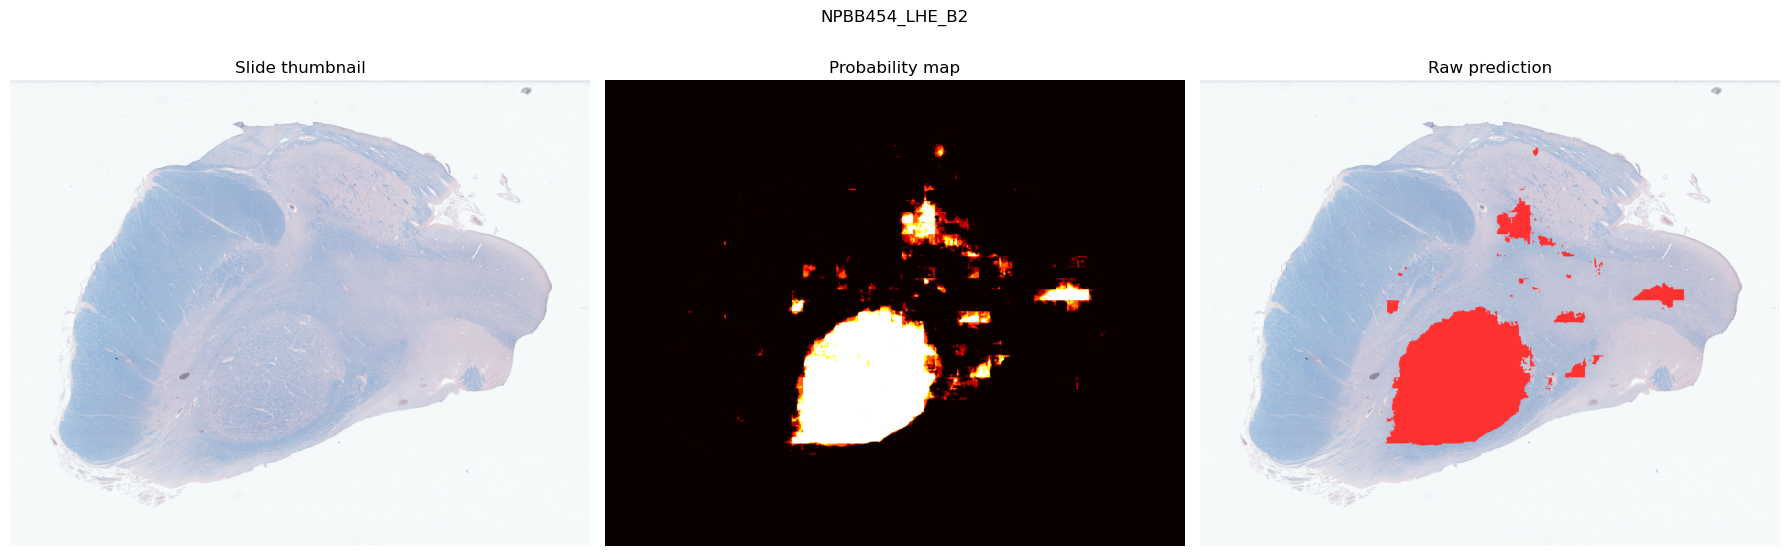

  After threshold:   2,564,078 pixels
  After dilation:    2,813,627 pixels
  After erosion:     2,649,225 pixels
  Regions kept:      45
  Saved: NPBB454_LHE_B2_thresh0.3_dil8.geojson
  After threshold:   2,480,292 pixels
  After dilation:    2,768,613 pixels
  After erosion:     2,561,769 pixels
  Regions kept:      36
  Saved: NPBB454_LHE_B2_thresh0.4_dil10.geojson
  After threshold:   2,331,534 pixels
  After dilation:    2,612,131 pixels
  After erosion:     2,407,250 pixels
  Regions kept:      24
  Saved: NPBB454_LHE_B2_thresh0.5_dil12.geojson


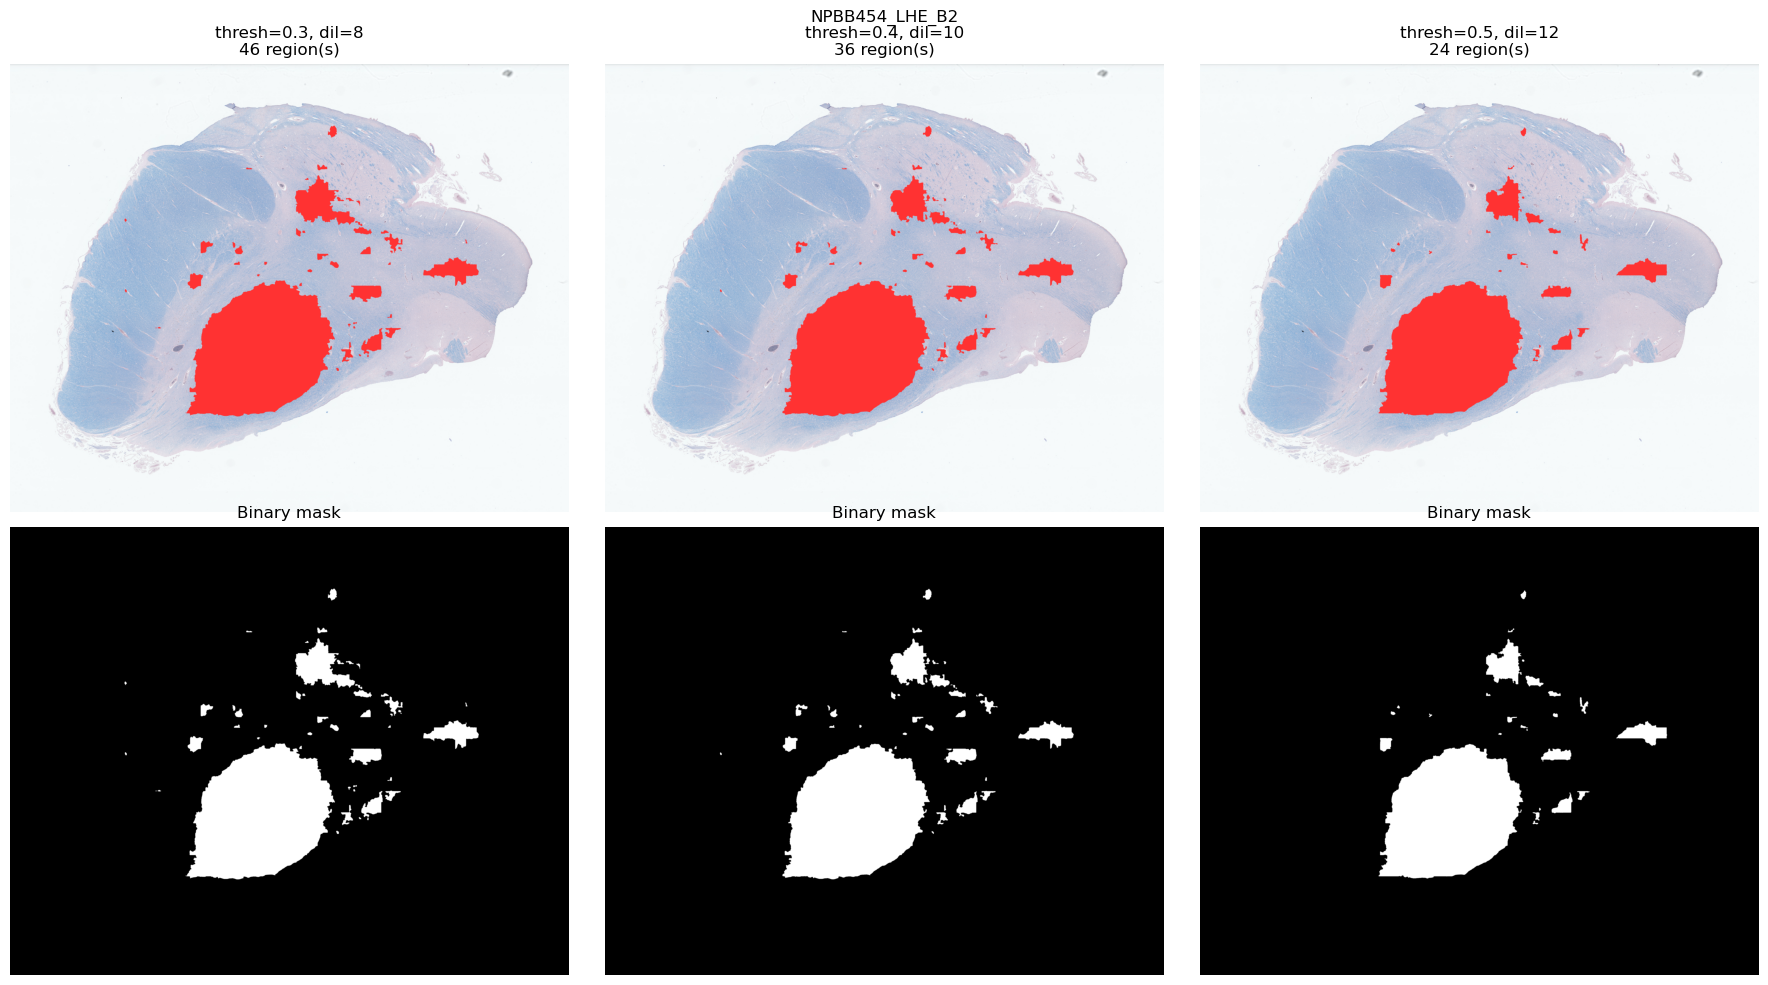


Predicting: NPBB194_4G8_B11
  Thumbnail: 6145 x 5504
  Prediction complete


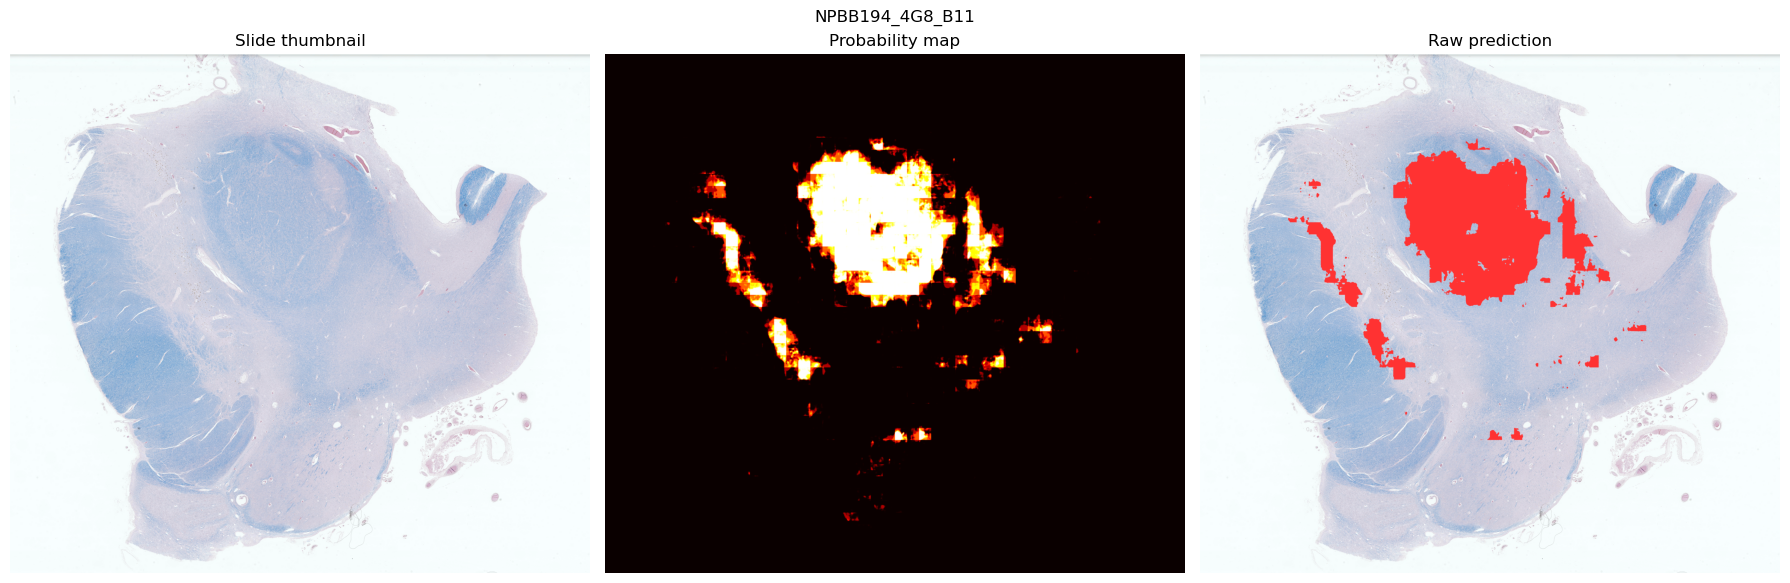

  After threshold:   2,597,430 pixels
  After dilation:    2,899,172 pixels
  After erosion:     2,705,405 pixels
  Regions kept:      30
  Saved: NPBB194_4G8_B11_thresh0.3_dil8.geojson
  After threshold:   2,487,484 pixels
  After dilation:    2,845,671 pixels
  After erosion:     2,609,268 pixels
  Regions kept:      32
  Saved: NPBB194_4G8_B11_thresh0.4_dil10.geojson
  After threshold:   2,276,710 pixels
  After dilation:    2,648,676 pixels
  After erosion:     2,386,340 pixels
  Regions kept:      29
  Saved: NPBB194_4G8_B11_thresh0.5_dil12.geojson


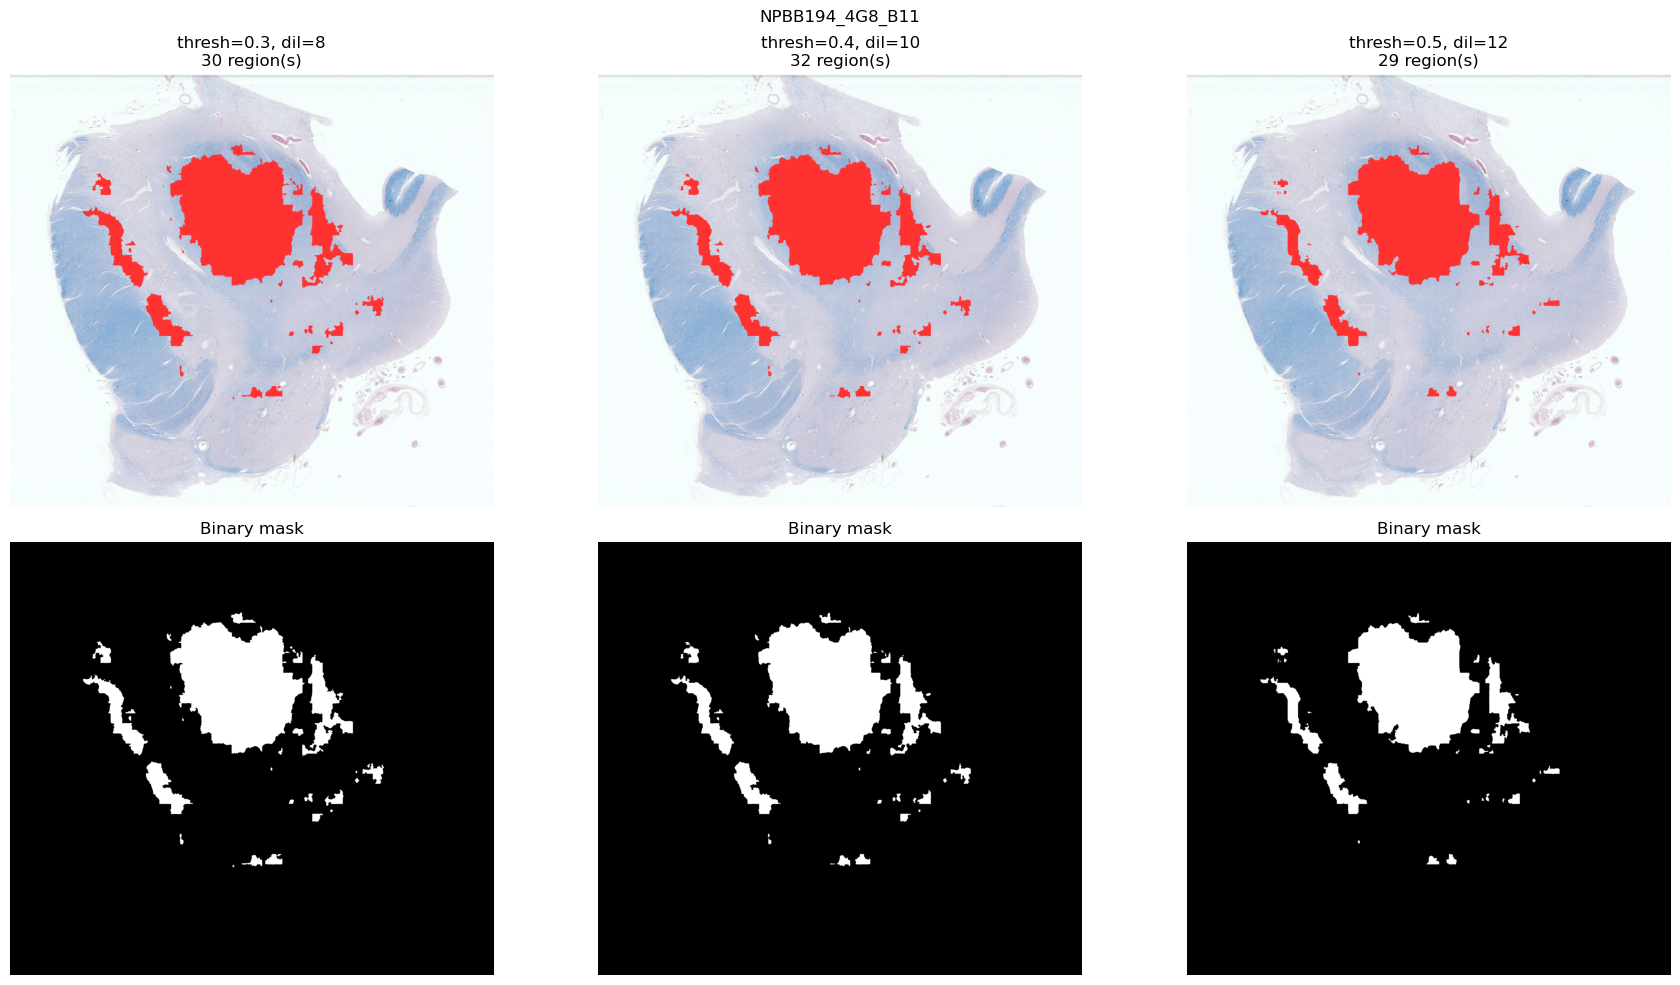


Predicting: NPBB203_LHE_B2
  Thumbnail: 5592 x 5052
  Prediction complete


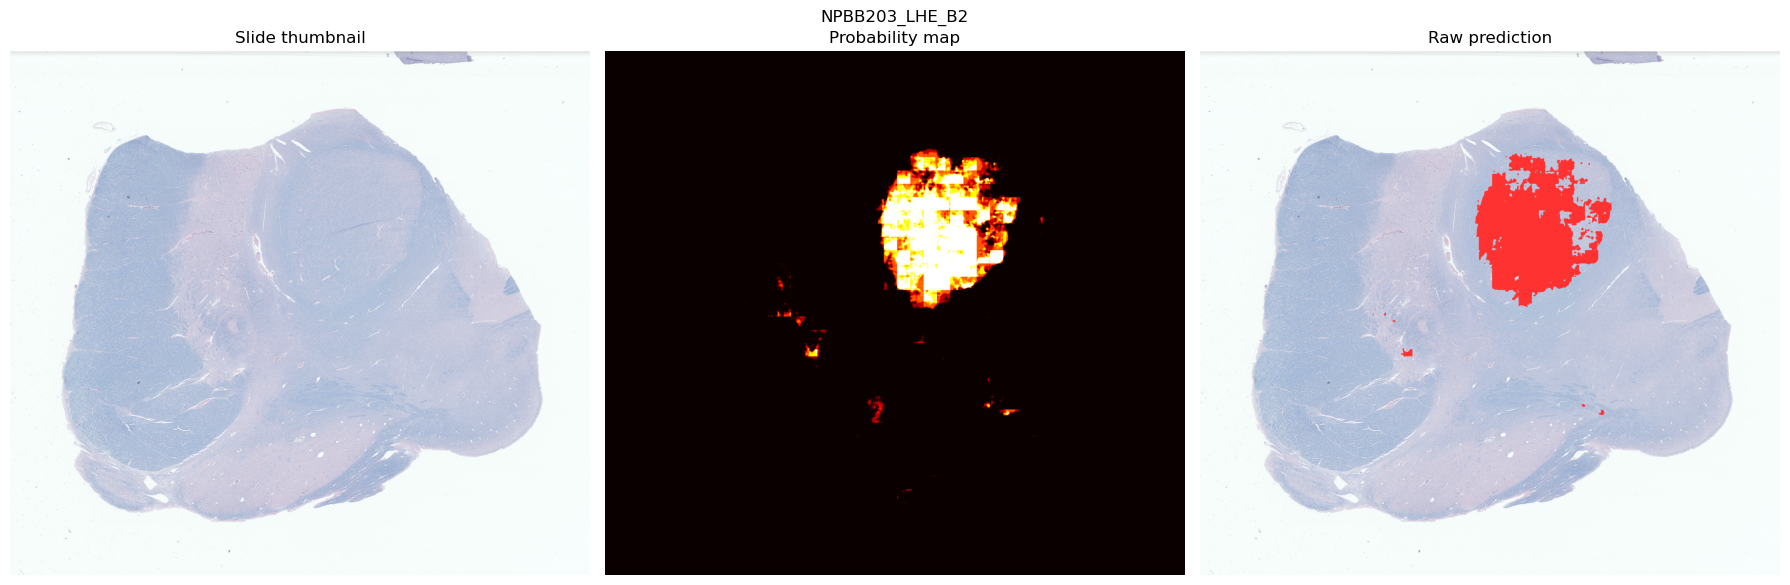

  After threshold:   1,294,438 pixels
  After dilation:    1,415,542 pixels
  After erosion:     1,372,558 pixels
  Regions kept:      12
  Saved: NPBB203_LHE_B2_thresh0.3_dil8.geojson
  After threshold:   1,235,903 pixels
  After dilation:    1,391,022 pixels
  After erosion:     1,331,051 pixels
  Regions kept:      10
  Saved: NPBB203_LHE_B2_thresh0.4_dil10.geojson
  After threshold:   1,115,811 pixels
  After dilation:    1,308,068 pixels
  After erosion:     1,211,080 pixels
  Regions kept:      7
  Saved: NPBB203_LHE_B2_thresh0.5_dil12.geojson


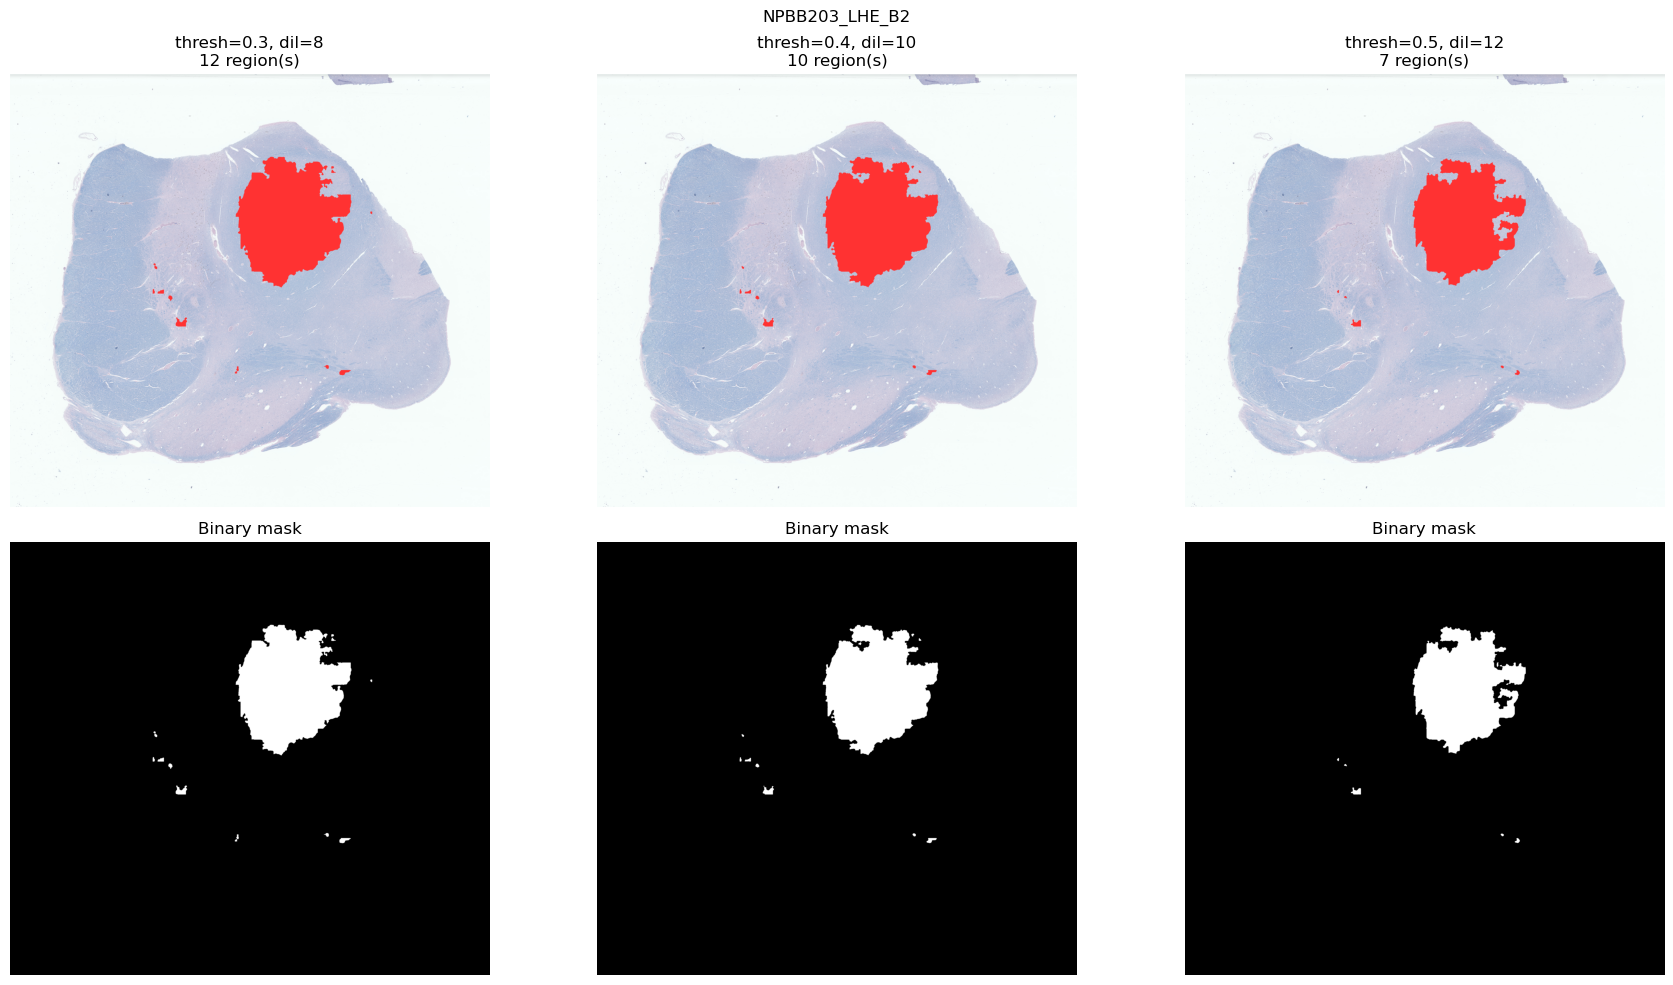


Predicting: NPBB439_LHE_B2
  Thumbnail: 6057 x 5102
  Prediction complete


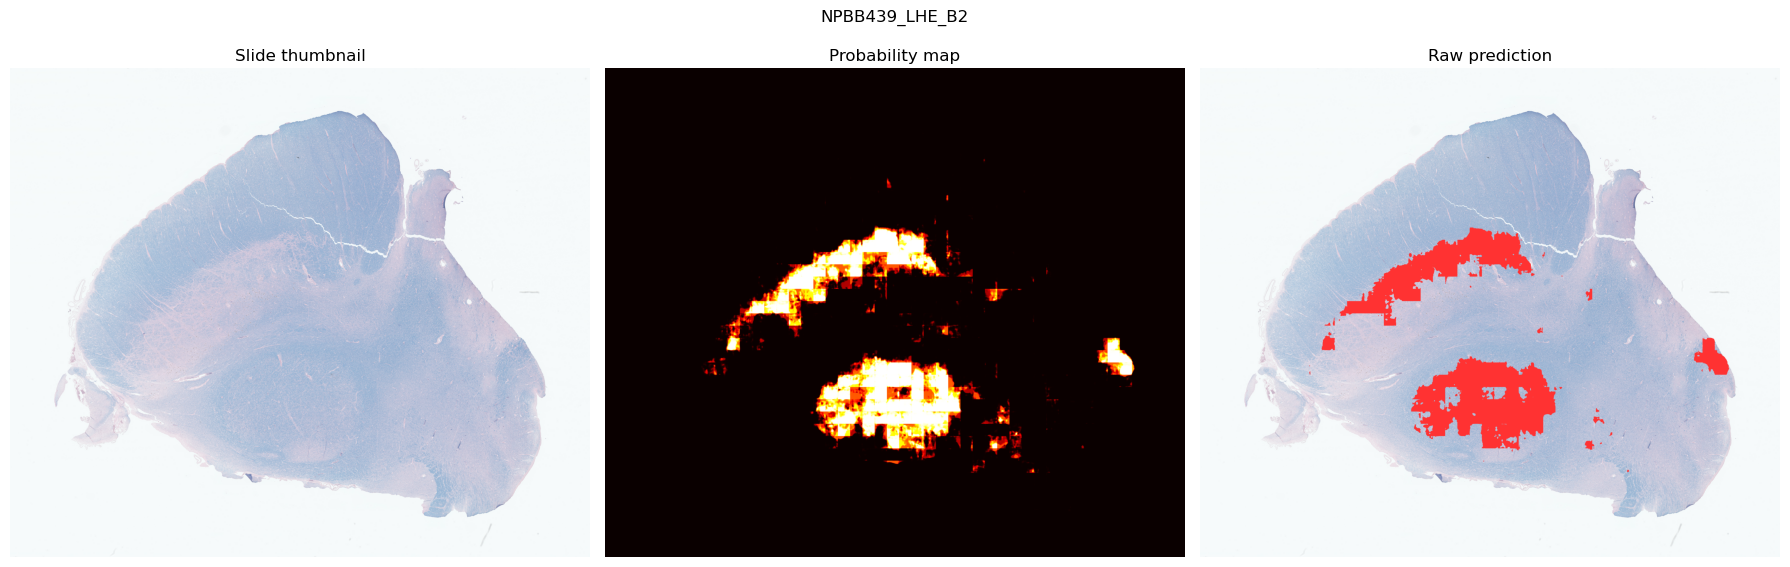

  After threshold:   1,887,329 pixels
  After dilation:    2,145,439 pixels
  After erosion:     1,991,358 pixels
  Regions kept:      32
  Saved: NPBB439_LHE_B2_thresh0.3_dil8.geojson
  After threshold:   1,784,996 pixels
  After dilation:    2,092,557 pixels
  After erosion:     1,903,455 pixels
  Regions kept:      28
  Saved: NPBB439_LHE_B2_thresh0.4_dil10.geojson
  After threshold:   1,604,528 pixels
  After dilation:    1,929,379 pixels
  After erosion:     1,758,625 pixels
  Regions kept:      16
  Saved: NPBB439_LHE_B2_thresh0.5_dil12.geojson


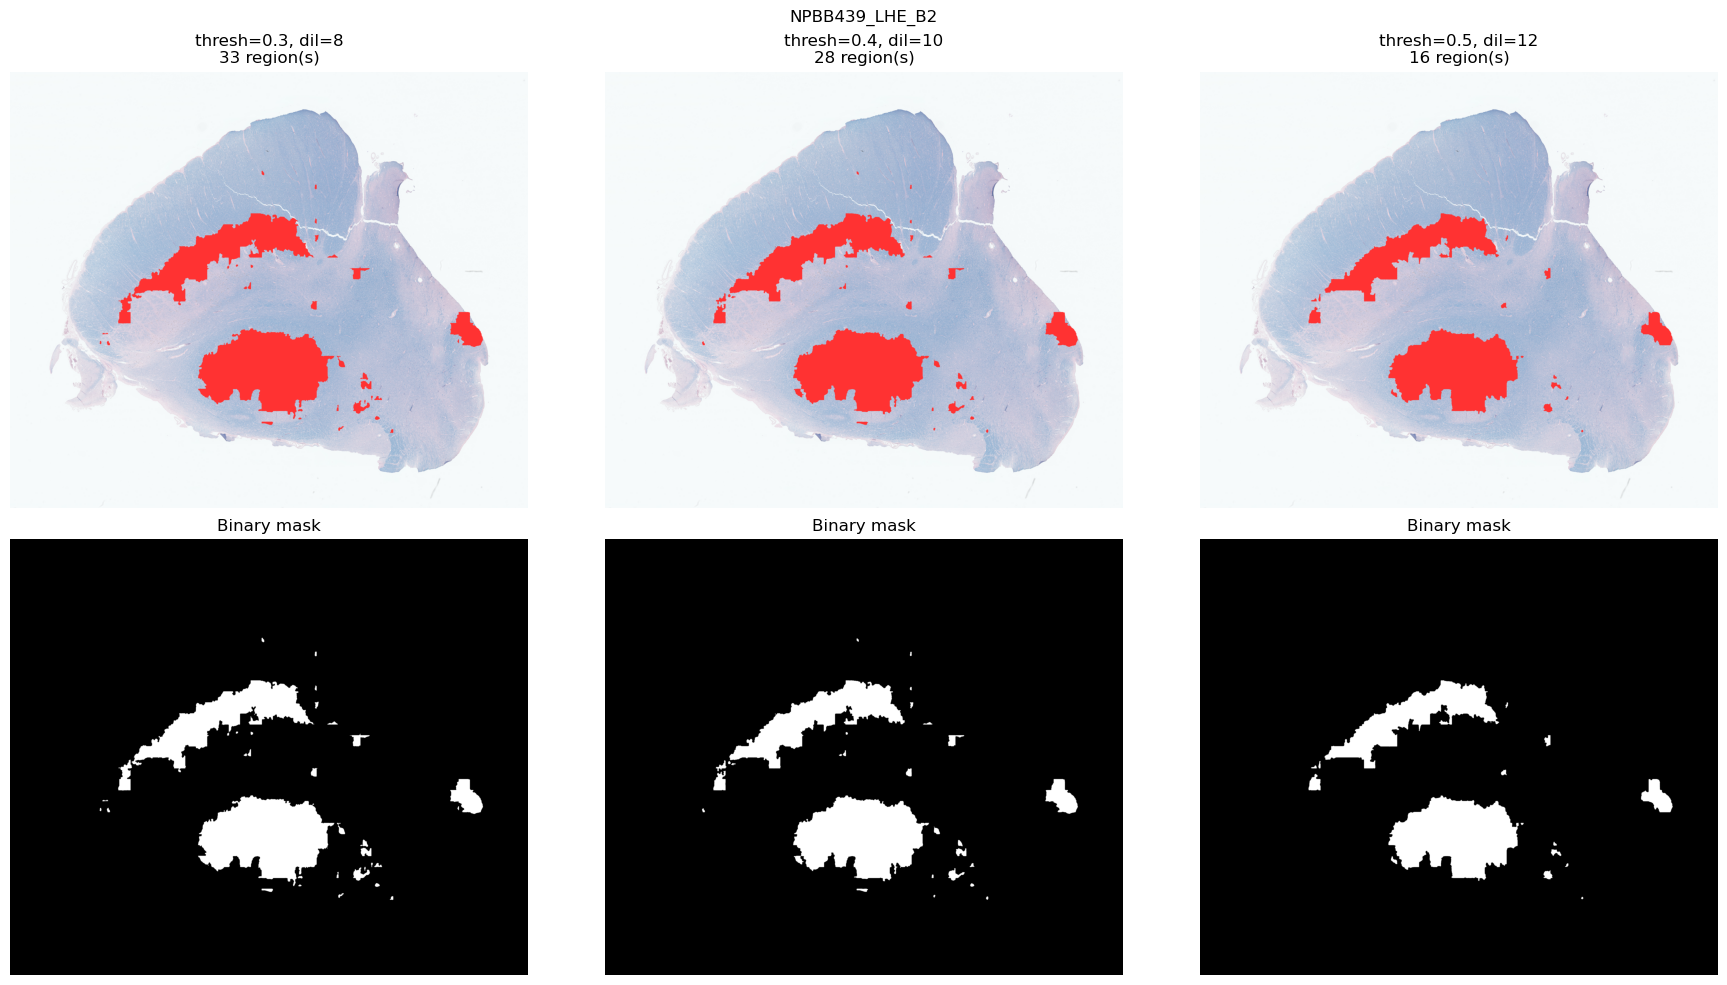


Predicting: NPBB227_LHE_A33
  Thumbnail: 6245 x 5504
  Prediction complete


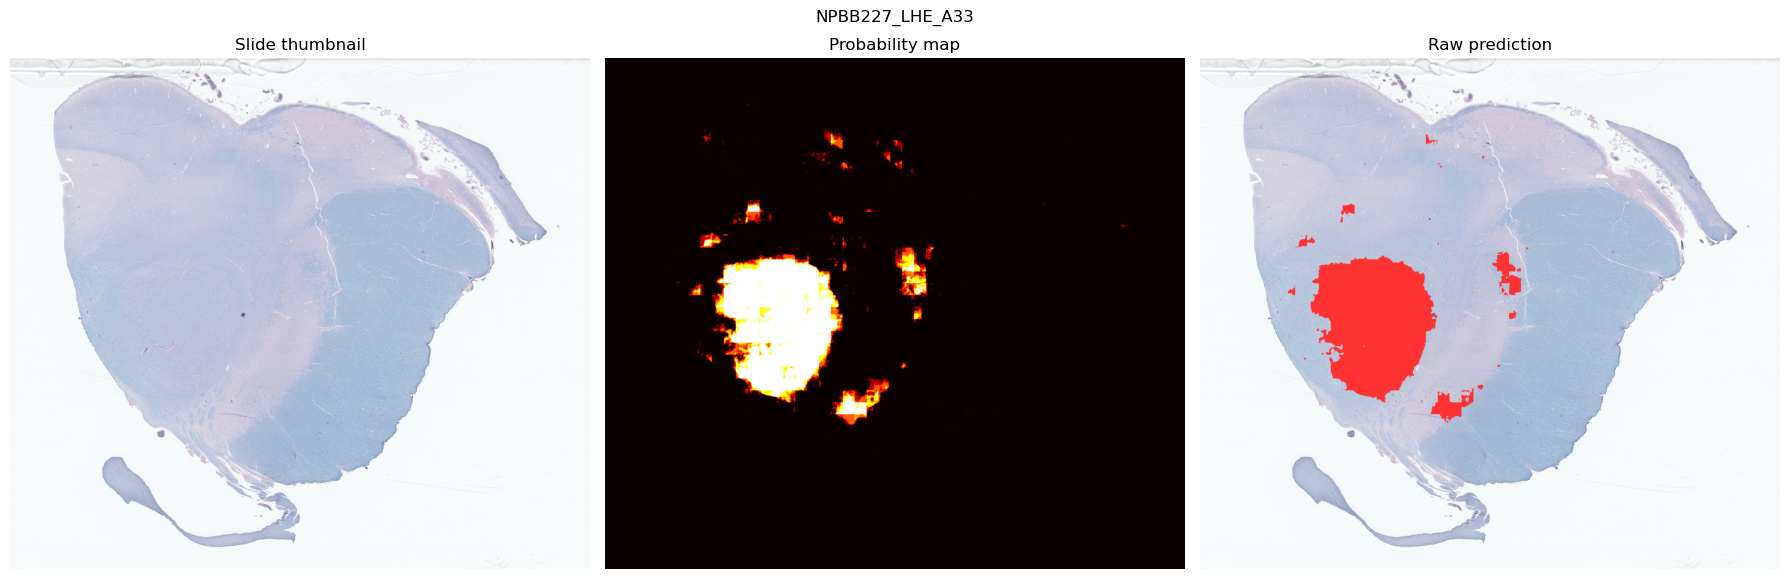

  After threshold:   1,838,500 pixels
  After dilation:    2,012,431 pixels
  After erosion:     1,899,257 pixels
  Regions kept:      23
  Saved: NPBB227_LHE_A33_thresh0.3_dil8.geojson
  After threshold:   1,773,490 pixels
  After dilation:    1,971,887 pixels
  After erosion:     1,841,335 pixels
  Regions kept:      20
  Saved: NPBB227_LHE_A33_thresh0.4_dil10.geojson
  After threshold:   1,653,301 pixels
  After dilation:    1,855,368 pixels
  After erosion:     1,716,737 pixels
  Regions kept:      14
  Saved: NPBB227_LHE_A33_thresh0.5_dil12.geojson


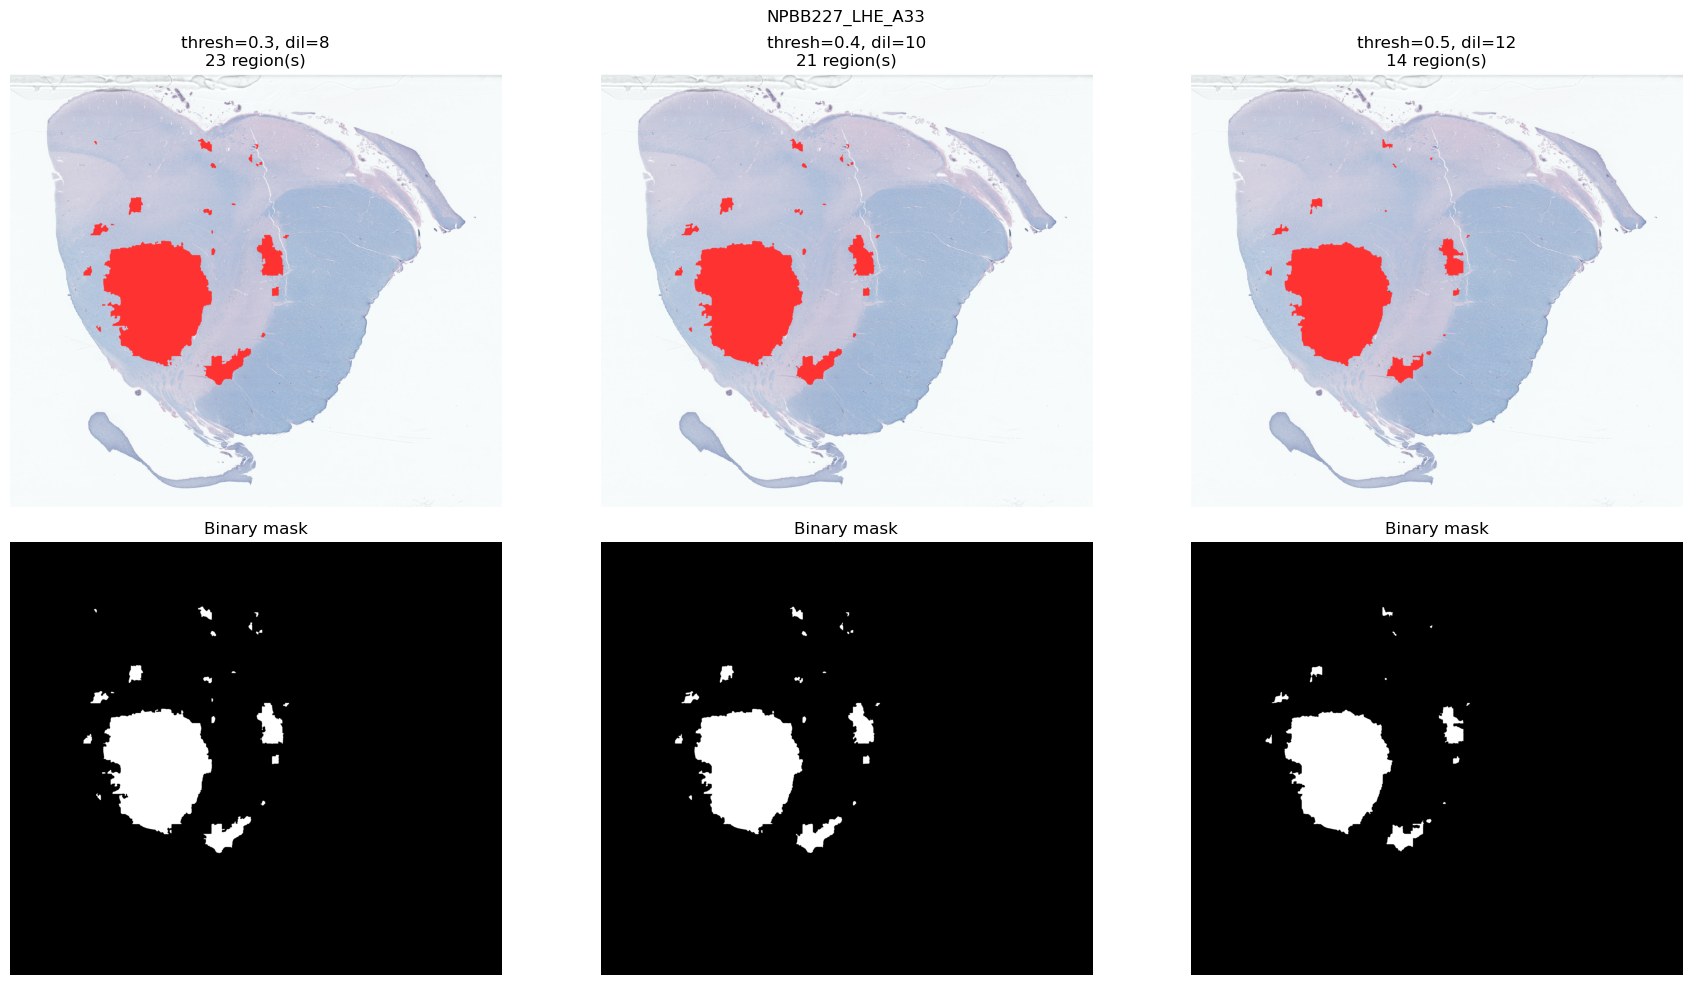

In [8]:
import glob
import json

all_slides  = glob.glob(os.path.join(SLIDE_DIR, "*.svs")) + \
              glob.glob(os.path.join(SLIDE_DIR, "*.tif"))
unannotated = [s for s in all_slides
               if not any(t in os.path.basename(s) for t in TRAINING_SLIDES)]

print(f"Unannotated slides: {len(unannotated)}")
for s in unannotated:
    print(f"  {os.path.basename(s)}")

torch.cuda.empty_cache()

for slide_path in unannotated:
    slide_name = os.path.splitext(os.path.basename(slide_path))[0]
    print(f"\nPredicting: {slide_name}")

    try:
        prob_map, thumb = predict_on_slide(slide_path, model)

        oslide           = openslide.OpenSlide(slide_path)
        base_w, base_h   = oslide.dimensions
        thumb_h, thumb_w = thumb.shape[:2]
        scale_x          = base_w / thumb_w
        scale_y          = base_h / thumb_h
        oslide.close()

        # Show raw thumbnail + probability map
        fig0, axes0 = plt.subplots(1, 3, figsize=(18, 6))
        axes0[0].imshow(thumb)
        axes0[0].set_title("Slide thumbnail")
        axes0[0].axis("off")
        axes0[1].imshow(prob_map, cmap="hot")
        axes0[1].set_title("Probability map")
        axes0[1].axis("off")
        overlay_raw = thumb.copy()
        overlay_raw[prob_map > 0.5] = [255, 50, 50]
        axes0[2].imshow(overlay_raw)
        axes0[2].set_title("Raw prediction")
        axes0[2].axis("off")
        plt.suptitle(slide_name)
        plt.tight_layout()
        plt.show()

        # Post-processing comparison
        settings = [
            {"threshold": 0.3, "dilation": 8,  "min_size": 500},
            {"threshold": 0.4, "dilation": 10, "min_size": 500},
            {"threshold": 0.5, "dilation": 12, "min_size": 500},
        ]

        fig, axes = plt.subplots(2, 3, figsize=(18, 10))
        for i, s in enumerate(settings):
            clean = postprocess_prediction(
                prob_map,
                threshold=s["threshold"],
                dilation_radius=s["dilation"],
                min_region_size=s["min_size"]
            )
            gj = mask_to_geojson(clean, scale_x, scale_y)

            overlay = thumb.copy()
            overlay[clean > 0] = [255, 50, 50]
            axes[0][i].imshow(overlay)
            axes[0][i].set_title(
                f"thresh={s['threshold']}, dil={s['dilation']}\n"
                f"{len(gj['features'])} region(s)"
            )
            axes[0][i].axis("off")
            axes[1][i].imshow(clean, cmap="gray")
            axes[1][i].set_title("Binary mask")
            axes[1][i].axis("off")

            out = os.path.join(PRED_DIR,
                f"{slide_name}_thresh{s['threshold']}_dil{s['dilation']}.geojson")
            with open(out, "w") as f:
                json.dump(gj, f)
            print(f"  Saved: {os.path.basename(out)}")

        plt.suptitle(slide_name)
        plt.tight_layout()
        plt.show()

    except Exception as e:
        import traceback
        print(f"  ERROR: {e}")
        traceback.print_exc()